In [28]:
import sys
sys.path.append(r'/Users/kostastsampourakis/Desktop/code/Python/projects/gaussfiltax')

import time

from jax import numpy as jnp
from jax import random as jr
from jax import lax, vmap, pmap, jacfwd, jacrev, debug, device_put, jit
from tensorflow_probability.substrates.jax.distributions import MultivariateNormalFullCovariance as MVN
from typing import List, Optional, NamedTuple, Union
from jaxtyping import Array, Float, Int
from sklearn.mixture import GaussianMixture

# import tensorflow as tf
# tf.test.gpu_device_name()

import gaussfiltax.utils as utils
import gaussfiltax.inference as gf
from gaussfiltax.inference import ParamsUKF, _ukf_predict_nonadditive, PosteriorGaussianSumFiltered, _process_input, _get_params, swap_axes_on_values
from gaussfiltax.models import ParamsNLSSM, NonlinearSSM, ParamsBPF


import matplotlib.pyplot as plt
import matplotlib_inline
matplotlib_inline.backend_inline.set_matplotlib_formats('svg')

In [29]:
@jit 
def KL_divergence(mu, Sigma, m, P) -> Float:
    return jnp.trace(jnp.linalg.inv(P) @ (Sigma - P + (mu - m) @ (mu - m).T)) + jnp.log(jnp.linalg.det(P) / jnp.linalg.det(Sigma))

@jit
def _cov_fn(C, weights, means, covs):
    mean_c = jnp.einsum('i,ij->j', weights[C], means[C]) / jnp.sum(weights[C])
    cov_c = (jnp.einsum('i,ijk->jk', weights[C], covs[C]) + jnp.einsum('i,ij->ij', weights[C], means[C]-mean_c).T @ (means[C]-mean_c) ) / jnp.sum(weights[C])
    return cov_c

def mixture_reduction(weights, means, covs, red_num, reps=100):
    prev_num = weights.shape[0]
    ext_weights = jnp.hstack([weights, jnp.array([0.])])
    ext_means = jnp.vstack([means, jnp.zeros(means.shape[1])])
    ext_covs = jnp.vstack((covs, jnp.array([jnp.zeros((covs.shape[1], covs.shape[2]))])))

    def _step(carry, r):
        prev_red_means, prev_red_covs = carry
        
        KLmat = vmap(lambda mu, Sigma: vmap(lambda m, P: KL_divergence(mu, Sigma, m, P))(prev_red_means, prev_red_covs))(means, covs)
        closest_comp = jnp.argmin(KLmat, axis=1)
        correspondence_mat = vmap(lambda l: jnp.where (closest_comp == l, jnp.arange(prev_num), -1))(jnp.arange(red_num))
        red_weights = vmap(lambda C: jnp.sum(ext_weights[C]))(correspondence_mat)
        red_means = vmap(lambda C: jnp.einsum('i,ij->j', ext_weights[C], ext_means[C]) / jnp.sum(ext_weights[C]))(correspondence_mat)
        red_covs = vmap(_cov_fn, in_axes=(0, None, None, None))(correspondence_mat, ext_weights, ext_means, ext_covs)

        red_means = jnp.where(jnp.isnan(red_means), prev_red_means, red_means)
        red_covs = jnp.where(jnp.isnan(red_covs), prev_red_covs, red_covs)

        carry = (red_means, red_covs)

        return carry, (red_weights, red_means, red_covs)
    
  

    # Assuming you have your data stored in a variable called 'data'
    # Specify the number of clusters (k) you want to initialize

    # Initialize GM
    # gm = GaussianMixture(n_components=red_num, random_state=0).fit(means)
    # red_means = gm.means_
    # red_covs = gm.covariances_

    red_means = jr.choice(jr.PRNGKey(0), means, shape=(red_num,))
    red_covs = jr.choice(jr.PRNGKey(0), covs, shape=(red_num,))
    carry = (red_means, red_covs)
    out = lax.scan(_step, carry, jnp.arange(reps))
    # out = _step(carry, jnp.arange(reps))

    return out[1]

    

In [30]:
num_comp = 100
weights = jnp.ones(num_comp) / num_comp
mu_array = jr.normal(jr.PRNGKey(0), (num_comp, 2))
Sigma_array = jnp.tile(jnp.eye(2), (num_comp, 1, 1))
# print(mu_array)

red_num = 20
weights, means, covs = mixture_reduction(weights, mu_array, Sigma_array, red_num)
# print('weights', weights[-1])
# print('means', means[-1])
# print('covs', covs[-1])

In [31]:
weights.shape

(100, 20)

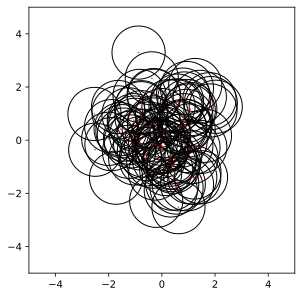

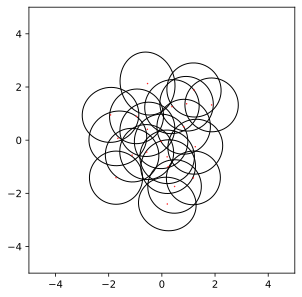

In [32]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Ellipse

def plot_gaussian_ellipses(means, covariances, xlim=10, ylim=10, ax=None):
    """
    Plot ellipses corresponding to 2D Gaussian distributions.
    
    Parameters:
    - means: List of means of the Gaussians. Each mean should be a 2-element array-like object.
    - covariances: List of 2x2 covariance matrices of the Gaussians.
    - ax: Matplotlib Axes object. If None, a new figure and axes will be created.
    """
    if ax is None:
        fig, ax = plt.subplots()

    for mean, cov in zip(means, covariances):
        eigenvalues, eigenvectors = jnp.linalg.eigh(cov)
        order = eigenvalues.argsort()[::-1]
        eigenvalues, eigenvectors = eigenvalues[order], eigenvectors[:, order]

        # Compute the angle of the ellipse
        angle = jnp.degrees(np.arctan2(*eigenvectors[:, 0][::-1]))

        # Compute width and height of the ellipse
        width, height = 2 * jnp.sqrt(eigenvalues)

        # Create and add the ellipse patch to the axes
        ellipse = Ellipse(xy=mean, width=width, height=height, angle=angle, edgecolor='black', fc='None')
        ax.add_patch(ellipse)
        ax.plot(*mean, 'ro', markersize=0.5)  # Plot the mean as a red point

    ax.set_xlim(-xlim, xlim)
    ax.set_ylim(-ylim, ylim)
    ax.set_aspect('equal', 'box')
    plt.show()


plot_gaussian_ellipses(mu_array, Sigma_array, xlim=5, ylim=5)
plot_gaussian_ellipses(means[-1], covs[-1], xlim=5, ylim=5)

In [33]:
# # Parameters
# state_dim = 4
# state_noise_dim = 2
# emission_dim = 2
# emission_noise_dim = 2
# seq_length = 500
# mu0 = 1.0 * jnp.array([-0.05, 0.001, 0.7, -0.05])
# q0 = jnp.zeros(state_noise_dim)
# r0 = jnp.zeros(emission_noise_dim)
# Sigma0 = 1.0 * jnp.array([[0.1, 0.0, 0.0, 0.0],[0.0, 0.005, 0.0, 0.0],[0.0, 0.0, 0.1, 0.0],[0.0, 0.0, 0.0, 0.01]])
# Q = 1e-5 * jnp.eye(state_noise_dim)
# R = 25*1e-6  * jnp.eye(emission_noise_dim)

# dt = 0.5
# FCV = 1.0 * jnp.array([[1, dt, 0, 0],[0, 1, 0, 0],[0, 0, 1, dt],[0, 0, 0, 1]])
# acc = 0.05
# Omega = lambda x, acc: acc / jnp.sqrt(x[1]**2 + x[3]**2)
# FCT =  lambda x, a: jnp.array([[1, jnp.sin(dt * Omega(x, a)) / Omega(x, a), 0, -(1-jnp.cos(dt * Omega(x, a))) / Omega(x, a)],
#                             [0, jnp.cos(dt * Omega(x, a)), 0, -jnp.sin(dt * Omega(x, a))],
#                             [0, (1-jnp.cos(dt * Omega(x, a))) / Omega(x, a), 1, jnp.sin(dt * Omega(x, a)) / Omega(x, a)],
#                             [0, jnp.sin(dt * Omega(x, a)), 0, jnp.cos(dt * Omega(x, a))]])

# G = jnp.array([[0.5, 0],[1, 0],[0, 0.5],[0, 1]])
# fBOT = lambda x, q, u: FCV @ x + G @ q
# fManBOT = lambda x, q, u: (0.5*(u-1)*(u-2)*FCV - u*(u-2)*FCT(x, acc) + 0.5*u*(u-1) * FCT(x, -acc)) @ x + G @ q
# gBOT = lambda x, r, u: jnp.arctan2(x[2], x[0]) + r
# gBOT2 = lambda x ,r, u: jnp.array([jnp.arctan2(x[2], x[0]), jnp.sqrt(x[0]**2 + x[2]**2)]) + r
# gBOTlp = lambda x, y, u: MVN(loc = gBOT2(x, r0, u), covariance_matrix = R).log_prob(y)
# # inputs = jnp.zeros((seq_length, 1))
# inputs = jnp.array([1]*int(2*seq_length/5) + [0]*int(seq_length/5) + [2]*int(2*seq_length/5)) # changepoint inputs
# # inputs = jr.choice(jr.PRNGKey(0), jnp.array([0, 1, 2]), shape = (seq_length, 1)) # random inputs
# # inputs = vmap(lambda x: 2 * jnp.sin(0.1 * x)**2)(jnp.arange(seq_length)) # sine
# f = fManBOT
# g = gBOT2
# glp = gBOTlp

In [34]:
# Parameters
state_dim = 4
state_noise_dim = 4
emission_dim = 4
emission_noise_dim = 4
seq_length = 200
mu0 = 0.0 * jnp.zeros(state_dim)
q0 = jnp.zeros(state_noise_dim)
r0 = 0.0001 * jnp.ones(emission_noise_dim)
Sigma0 = 1.0 * jnp.eye(state_dim)
Q = 10.0 * jnp.eye(state_noise_dim)
R = 3 * 1e-2 * jnp.eye(emission_noise_dim)

# Model functions
Phi = 0.8 * jnp.eye(state_dim)
fmsv = lambda x, q, u: Phi @ x + q

sigma = 4.0
beta = 0.5
H0 = jnp.eye(emission_dim, state_dim)
glmsv = lambda x, r, u: u * beta * jnp.multiply(jnp.exp(x / sigma), r) + (1-u) * (H0 @ x + r)
def lmsvlp(x,y,u):
    M = u * beta * jnp.diag(jnp.exp(x / sigma)) + (1-u) * jnp.eye(emission_dim)
    return MVN(loc = glmsv(x, r0, u), covariance_matrix = M @ R @ M.T).log_prob(y)

# Inputs
# inputs = jnp.array([0]*int(seq_length/2) + [1]*int(seq_length/2)) # off - on
inputs = vmap(lambda x: jnp.sin(0.1 * x)**2)(jnp.arange(seq_length)) # sine_sq
# inputs = vmap(lambda x: (1 - jnp.sin(0.1 * x))/2)(jnp.arange(seq_length)) # sine
# inputs = jr.uniform(jr.PRNGKey(0), (seq_length,))
# inputs = jnp.zeros(seq_length) # off
# inputs = jnp.ones(seq_length) # on
# plt.plot(inputs)
# plt.show()

f = fmsv
g = glmsv
glp = lmsvlp

In [35]:
model = NonlinearSSM(state_dim, state_noise_dim, emission_dim, emission_noise_dim)
params = ParamsNLSSM(
    initial_mean=mu0,
    initial_covariance=Sigma0,
    dynamics_function=f,
    dynamics_noise_bias= q0,
    dynamics_noise_covariance=Q,
    emission_function=g,
    emission_noise_bias= r0,
    emission_noise_covariance=R,
)

params_bpf = ParamsBPF(
    initial_mean=mu0,
    initial_covariance=Sigma0,
    dynamics_function=f,
    dynamics_noise_bias=q0,
    dynamics_noise_covariance=Q,
    emission_function=g,
    emission_noise_bias=r0,
    emission_noise_covariance=R,
    emission_distribution_log_prob = glp
)
## Experiments
verbose = False
Nsim = 20
mix_agsf_mse = jnp.zeros(Nsim)
agsf_mse = jnp.zeros(Nsim)

mix_agsf_norm = jnp.zeros((Nsim, seq_length))
agsf_norm = jnp.zeros((Nsim, seq_length))

mix_agsf_time = jnp.zeros(Nsim)
agsf_time = jnp.zeros(Nsim)

next_key = jr.PRNGKey(0)
for i in range(Nsim):
    print('sim {}/{}'.format(i+1, Nsim))
    # Generate Data
    key0, key, next_key = jr.split(next_key, 3)
    print('key0: ', key0)
    print('key: ', key)
    states, emissions = model.sample(params, key0, seq_length, inputs = inputs)

    # Mixture AGSF
    opt_args = (0.9, 0.4)
    num_components = [2, 2, 2]
    tin = time.time()
    posterior_filtered_mix_agsf, aux_outputs_mix_agsf = gf.mixture_reduction_agsf(params, emissions, num_components, rng_key = key, opt_args = opt_args, inputs=inputs)    
    point_estimate_mix_agsf = jnp.sum(jnp.einsum('ijk,ij->ijk', posterior_filtered_mix_agsf.means, posterior_filtered_mix_agsf.weights), axis=0)
    tout = time.time()
    t_mix_agsf= tout - tin
    print('       Time taken for AGSF: ', tout - tin)

    # AGSF
    num_components = [1000, 5, 5]
    tin = time.time()
    # posterior_filtered_uagsf, aux_outputs = gf.unscented_agsf(params, uparams, emissions, num_components, rng_key = key, opt_args = opt_args, inputs=inputs)
    posterior_filtered_agsf, aux_outputs_agsf = gf.speedy_augmented_gaussian_sum_filter(params, emissions, num_components, rng_key = key, opt_args = opt_args, inputs=inputs)   
    point_estimate_agsf = jnp.sum(jnp.einsum('ijk,ij->ijk', posterior_filtered_agsf.means, posterior_filtered_agsf.weights), axis=0)
    tout = time.time()
    t_agsf= tout - tin
    print('       Time taken for UAGSF: ', tout - tin)

    # Computation of errors

    mix_agsf_norm = mix_agsf_norm.at[i].set(jnp.linalg.norm(point_estimate_mix_agsf[:,(0,2)] - states[:,(0,2)], axis = 1))
    agsf_norm = agsf_norm.at[i].set(jnp.linalg.norm(point_estimate_agsf[:,(0,2)] - states[:,(0,2)], axis = 1))

    mix_agsf_mse = mix_agsf_mse.at[i].set(jnp.mean(mix_agsf_norm[i]))
    agsf_mse = agsf_mse.at[i].set(jnp.mean(agsf_norm[i]))

    mix_agsf_time = mix_agsf_time.at[i].set(t_mix_agsf)
    agsf_time = agsf_time.at[i].set(t_agsf)


sim 1/20
key0:  [2467461003  428148500]
key:  [3186719485 3840466878]
       Time taken for AGSF:  1.616879940032959
       Time taken for UAGSF:  5.587059259414673
sim 2/20
key0:  [4038682467 4049047219]
key:  [1123993949 1633776119]
       Time taken for AGSF:  1.5752580165863037
       Time taken for UAGSF:  5.28668212890625
sim 3/20
key0:  [3295730785 1907469606]
key:  [2175656443 3507338041]
       Time taken for AGSF:  1.6835651397705078
       Time taken for UAGSF:  5.187749147415161
sim 4/20
key0:  [1795368326  584935165]
key:  [1120832370 3770592918]
       Time taken for AGSF:  1.652313232421875
       Time taken for UAGSF:  5.277083873748779
sim 5/20
key0:  [ 456292018 1165566599]
key:  [4102745572 3277364256]
       Time taken for AGSF:  1.798691987991333
       Time taken for UAGSF:  5.280696868896484
sim 6/20
key0:  [212254551 972031800]
key:  [4176427977  237722671]
       Time taken for AGSF:  1.5653021335601807
       Time taken for UAGSF:  5.287091970443726
sim 7/20
k

In [36]:
import pandas as pd

ind_mix_agsf = jnp.unique(jnp.argwhere(jnp.isnan(mix_agsf_mse)))
mix_agsf_mse = jnp.delete(mix_agsf_mse, ind_mix_agsf, axis = 0)
mix_agsf_success_pct = int(100 - 100*len(ind_mix_agsf) / Nsim)

ind_agsf = jnp.unique(jnp.argwhere(jnp.isnan(agsf_mse)))
agsf_mse = jnp.delete(agsf_mse, ind_agsf, axis = 0)
agsf_success_pct = int(100 - 100*len(ind_agsf) / Nsim)


keys = jr.split(jr.PRNGKey(0), 7)
B = 100
mix_agsf_boot = utils.bootstrap(keys[2], mix_agsf_mse, B)
agsf_boot = utils.bootstrap(keys[3], agsf_mse, B)

mix_agsf_amse = jnp.mean(mix_agsf_boot)
agsf_amse = jnp.mean(agsf_boot)

mix_agsf_atime = jnp.mean(mix_agsf_time)
agsf_atime = jnp.mean(agsf_time)

mix_agsf_tab_out = '${:2.3f}\pm{:2.3f}({}\%)$'.format(mix_agsf_amse, jnp.std(mix_agsf_boot), mix_agsf_success_pct)
agsf_tab_out = '${:2.3f}\pm{:2.3f}({}\%)$'.format(agsf_amse, jnp.std(agsf_boot), agsf_success_pct)

mix_agsf_tab_out1 = '${:2.2f}\pm{:2.2f}$'.format(mix_agsf_atime, jnp.std(agsf_time))
agsf_tab_out1 = '${:2.2f}\pm{:2.2f}$'.format(agsf_atime, jnp.std(agsf_time))

df = pd.DataFrame(columns = [' ','RMSE','time(s)'])
# df[' '] = ['GSF', 'AGSF', 'AGSF Optimal', 'BPF']
# df['RMSE'] = [gsf_tab_out, agsf_tab_out, agsf_opt_tab_out, bpf_tab_out]
# df['time(s)'] = [gsf_tab_out1, agsf_tab_out1, agsf_opt_tab_out1, bpf_tab_out1]
df[' '] = ['mix AGSF', 'AGSF']
df['RMSE'] = [mix_agsf_tab_out, agsf_tab_out]
df['time(s)'] = [mix_agsf_tab_out1, agsf_tab_out1]
print(df.to_latex(index=False))
df

\begin{tabular}{lll}
\toprule
  & RMSE & time(s) \\
\midrule
mix AGSF & $1.353\pm0.119(95\%)$ & $1.70\pm0.18$ \\
AGSF & $0.919\pm0.025(100\%)$ & $5.36\pm0.18$ \\
\bottomrule
\end{tabular}



,,RMSE,time(s)
0,mix AGSF,$1.353\pm0.119(95\%)$,$1.70\pm0.18$
1,AGSF,$0.919\pm0.025(100\%)$,$5.36\pm0.18$
